#Name: Ashraful Islam Shohan
#Email: aishohan001@gmail.com

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

In [55]:
df = pd.read_csv("titanic_data_updated.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,no,second,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,yes,first,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,no,third,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,yes,first,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


# Question 1
## Load the Titanic dataset and display:
- Dataset shape
- First 10 rows
- 5 random samples



In [56]:
dataSetShape = df.shape
firstTenRow = df.head(10)
randomFiveSample = df.sample(5)
print(dataSetShape)
print(firstTenRow)
print(randomFiveSample)

(891, 12)
   PassengerId Survived  Pclass  \
0            1       no   third   
1            2      yes   first   
2            3      yes   third   
3            4      yes   first   
4            5       no   third   
5            6       no   third   
6            7       no   first   
7            8       no   third   
8            9      yes   third   
9           10      yes  second   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   
5                                   Moran, Mr. James    male   NaN      0   
6                            McCarthy, Mr. Timothy J    male  54.

# Question 2
## Perform feature screening on the Titanic dataset by:
- Finding total missing values
- Finding duplicate rows
- Removing duplicate rows permanently


In [57]:
totalMissionValue = df.isnull().sum().sum()
duplicateRow = df[df.duplicated()]
removeDuplicateRow = df.drop_duplicates(inplace=True)
print("totalMissionValue: ",totalMissionValue)
print("duplicateRow: ",duplicateRow)
print("removeDuplicateRow: ",removeDuplicateRow)

totalMissionValue:  866
duplicateRow:  Empty DataFrame
Columns: [PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked]
Index: []
removeDuplicateRow:  None


# Question 3
## Perform statistical profiling of the Titanic dataset and display:
- Dataset information
- Statistical summary of numerical columns
- Also write 2 observations from the output.


In [58]:
datasetInfo = df.info()
dataSummary = df.describe()
print(datasetInfo)
print(dataSummary)
print("----------")
print("My obserbation: (1).total value we can get from passengerId is 891, there are three place where value is mission Age, Cabin and Embarked (2).from the data we can see that the avarage fare is 32.204 and highest is more than 500 doller, it means who are ride on ship are quite rich people")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    object 
 2   Pclass       891 non-null    object 
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(3), object(7)
memory usage: 83.7+ KB
None
       PassengerId         Age       SibSp       Parch        Fare
count   891.000000  714.000000  891.000000  891.000000  891.000000
mean    446.000000   29.699118    0.523008    0.381594   32.204208
std     257.353842   14.526497    1.10

# Question 4
## Perform univariate categorical analysis on the Survived column by:
- Creating a countplot
- Calculating percentage distribution
- Creating a pie chart
### Write 2 insights from the analysis.


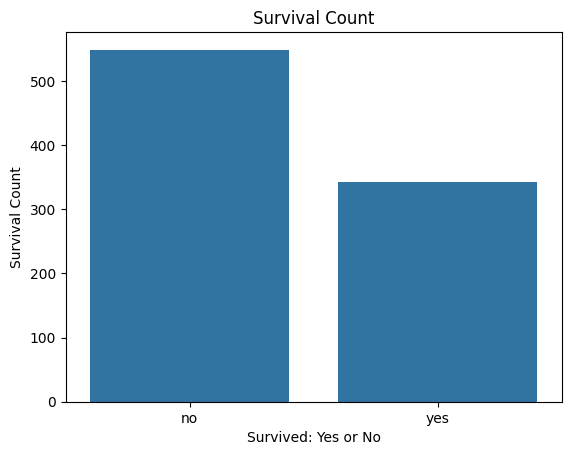

Survived
no     61.616162
yes    38.383838
Name: proportion, dtype: float64


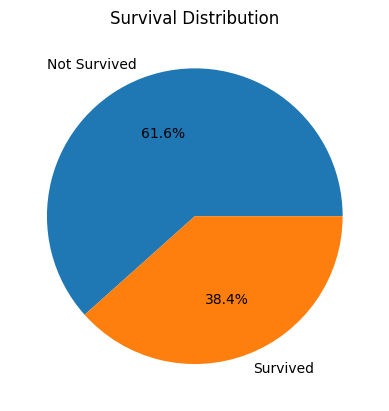

--------------
Two in sights with this analysis: (1). we can see from this graph that there are more people who can not survived than who survived, (2).more than 500 people who can not survived whereas 300 people who actually in this dataset


In [59]:
sns.countplot(data= df ,x='Survived')

plt.title("Survival Count")
plt.xlabel("Survived: Yes or No")
plt.ylabel("Survival Count")
plt.show()


Survival_parcentage = df["Survived"].value_counts(normalize= True) * 100;
print(Survival_parcentage)


Survival_count = df["Survived"].value_counts()
plt.pie(Survival_count, labels= ["Not Survived", "Survived"], autopct="%1.1f%%")
plt.title("Survival Distribution")
plt.show()

print("--------------")

print("Two in sights with this analysis: (1). we can see from this graph that there are more people who can not survived than who survived, (2).more than 500 people who can not survived whereas 300 people who actually in this dataset")

# Question 5
## Perform univariate numerical analysis on the Age column by:
- Creating a histogram
- Creating a KDE plot
### Write 2 observations from the plots.


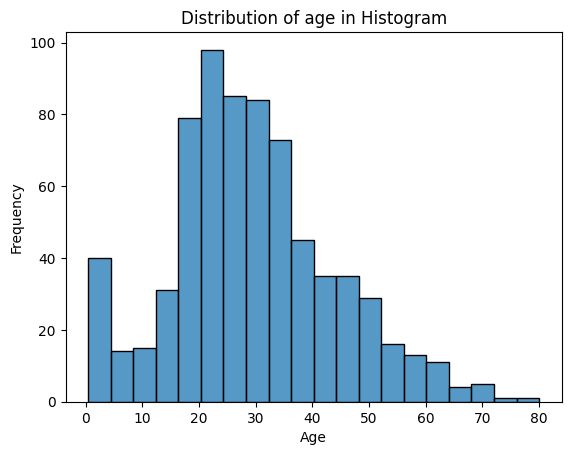

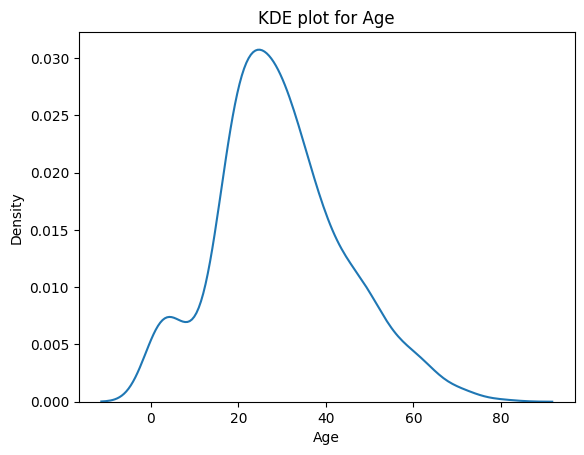

------------
Observations: (1).Around age 18 to 38 has the hieghest concentration people that was exist in that titanic (2)From the kde plot we can observe graph is right-skewed that means there are fewer people are old among those passengers


In [60]:
sns.histplot(data = df, x='Age', bins=20)
plt.title("Distribution of age in Histogram")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


sns.kdeplot(data = df, x="Age")
plt.title("KDE plot for Age")
plt.xlabel("Age")
plt.ylabel("Density")
plt.show()

print("------------")

print("Observations: (1).Around age 18 to 38 has the hieghest concentration people that was exist in that titanic (2)From the kde plot we can observe graph is right-skewed that means there are fewer people are old among those passengers")



#Question 6
- Perform multivariate analysis between Sex and Survived using a countplot with hue.
- Also calculate normalized survival ratios using groupby().
### Write 2 insights from the analysis.


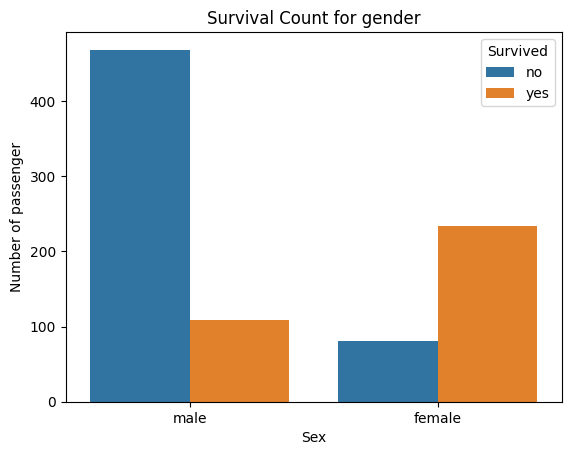

Sex     Survived
female  yes         0.742038
        no          0.257962
male    no          0.811092
        yes         0.188908
Name: proportion, dtype: float64
---------------
Insight analysis: (1)Female passengers are significantly higher survival rate than male (2).More than 400 male died, where less than 100 female died.


In [61]:
sns.countplot(data = df, x='Sex', hue='Survived')

plt.title("Survival Count for gender")
plt.ylabel("Number of passenger")
plt.show()

survival_ratio = df.groupby('Sex')['Survived'].value_counts(normalize=True)
print(survival_ratio)

print("---------------")
print("Insight analysis: (1)Female passengers are significantly higher survival rate than male (2).More than 400 male died, where less than 100 female died.")


# Question 7
- Create a barplot showing the relationship between Pclass and Fare.
##  Write 2 observations from the visualization.


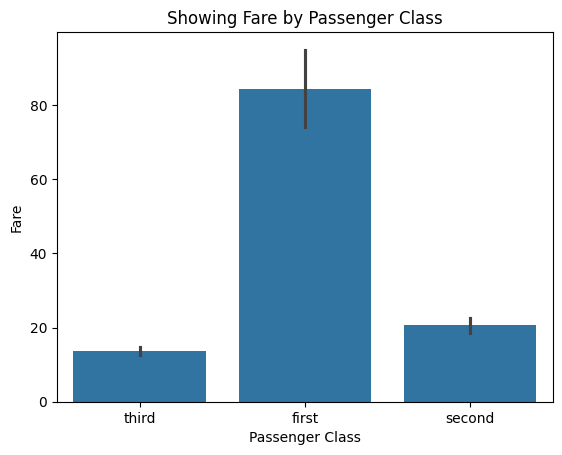

--------------------
Two observation: (1)First class passnger paid the highest ammount of fare, then second class and then third class (2).First class passenger paid more than 80 doller on avarge , second class around 20 and third class less than 20 doller.


In [62]:
sns.barplot(data = df, x= "Pclass", y = "Fare")
plt.title('Showing Fare by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Fare')

plt.show()

print("--------------------")

print("Two observation: (1)First class passnger paid the highest ammount of fare, then second class and then third class (2).First class passenger paid more than 80 doller on avarge , second class around 20 and third class less than 20 doller.")

# Question 8
- Create a KDE plot to compare the Age distribution of survived and non-survived passengers.
## Write 2 insights from the graph.


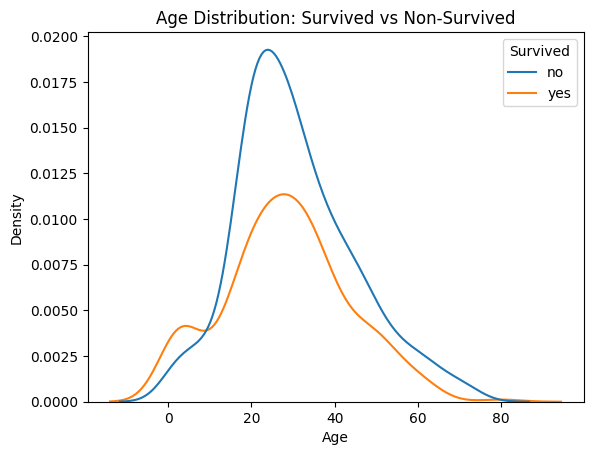

-----------
Insight from the graph: (1). here we can see from the graph that large number of youung people are non-surviving around 20 to 25 (2). Among very young passenger surviving rate is higher so they have better chance of surviving.


In [63]:
sns.kdeplot(data = df, x='Age', hue='Survived')

plt.title('Age Distribution: Survived vs Non-Survived')
plt.xlabel('Age')
plt.ylabel('Density')
plt.show()


print("-----------")
print("Insight from the graph: (1). here we can see from the graph that large number of youung people are non-surviving around 20 to 25 (2). Among very young passenger surviving rate is higher so they have better chance of surviving.")

# Question 9
## Perform feature engineering and train-test split by:
- Dropping PassengerId, Name, and Ticket columns
- Separating features (X) and target (y)
- Splitting the dataset using test_size=0.2 and random_state=42
### Display the shapes of train and test datasets.


In [64]:
df.drop(
    ["PassengerId","Name","Ticket"],
    axis= 1,
    inplace = True
)

x= df.drop("Survived",axis=1)
y = df["Survived"]

x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size = 0.2, random_state=42
)

print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

x_train shape: (712, 8)
x_test shape: (179, 8)
y_train shape: (712,)
y_test shape: (179,)


# Question 10
Handle missing values in the Titanic dataset by:
- Imputing missing Age values using SimpleImputer with mean strategy
- Imputing missing Embarked values using most frequent strategy
- Imputing missing Cabin values using constant strategy with "Missing"
### Finally, check whether any missing values remain.


In [65]:
age_imputer = SimpleImputer(missing_values=np.nan , strategy='mean')
age_imputer.fit(x_train[['Age']])
x_train['Age'] = age_imputer.transform(x_train[['Age']]).ravel()

x_test['Age'] = age_imputer.transform(
    x_test[['Age']]
).ravel()



embarked_imputer = SimpleImputer(
    missing_values=np.nan,
    strategy='most_frequent'
)
embarked_imputer.fit(x_train[['Embarked']])
x_train['Embarked'] = embarked_imputer.transform(
    x_train[['Embarked']]
).ravel()

x_test['Embarked'] = embarked_imputer.transform(
    x_test[['Embarked']]
).ravel()



cabin_imputer = SimpleImputer(
    missing_values=np.nan,
    strategy='constant',
    fill_value='Missing'
)
cabin_imputer.fit(x_train[['Cabin']])
x_train['Cabin'] = cabin_imputer.transform(
    x_train[['Cabin']]
).ravel()

x_test['Cabin'] = cabin_imputer.transform(
    x_test[['Cabin']]
).ravel()



print("Training missing values:")
print(x_train.isnull().sum())

print("\nTesting missing values:")
print(x_test.isnull().sum())

print("\nTotal missing values in X_train:", x_train.isnull().sum().sum())
print("Total missing values in X_test:", x_test.isnull().sum().sum())

Training missing values:
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Cabin       0
Embarked    0
dtype: int64

Testing missing values:
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Cabin       0
Embarked    0
dtype: int64

Total missing values in X_train: 0
Total missing values in X_test: 0
